# Predicción de entregas tardías en Olist
## Red neuronal y análisis de escalabilidad · Laboratorio Semana 15

**Data Analytics ML Challenge · 2026-2**
Profesor: Elias Buitrago Bolivar · Universidad Central
Caso: *Brazilian E-Commerce Public Dataset by Olist*

---

**Objetivo.** Determinar si una red neuronal (perceptrón multicapa) identifica mejor los pedidos que llegarían tarde que la regresión logística de las semanas 12 y 14, y qué ocurre con el tiempo de cómputo y el tamaño del modelo cuando crece el volumen de datos.

**Pregunta del reto.** ¿Una red neuronal aporta valor?

**Contenido**

1. Carga de datos
2. Preparación de variables
3. Modelo de referencia
4. Regresión logística frente a redes neuronales
5. Umbral de decisión y costo
6. Escalabilidad
7. Interpretación de negocio
8. Autoverificación y registro de resultados

> Las secciones 1 a 3 son las mismas de las semanas anteriores (mismo ID, misma semilla, mismas particiones). El conjunto de **prueba no se utiliza** en este laboratorio.

## 1. Carga de datos

Una observación del modelo corresponde a un pedido, aunque tenga varios productos y pagos. Se integrarán siete tablas del conjunto público de Olist.

In [1]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)

In [2]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables

Un pedido puede contener varios ítems y pagos. Primero se resumen estas tablas por `order_id`, para evitar contar un mismo pedido varias veces. Las variables de destino se construyen después y no se incluyen entre los predictores.

In [3]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [4]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [5]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo

Se utilizarán datos que razonablemente están disponibles al cierre de la compra: plazo prometido, calendario, contenido del pedido, dimensiones de los productos, ubicación y medio de pago. Las fechas reales de envío y entrega, y las reseñas posteriores, quedan excluidas de las variables predictoras.

La lista de variables y sus tablas de origen se encuentra en el diccionario técnico anexo.

In [6]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual

Cada estudiante utilizará 35.000 pedidos, seleccionados a partir del ID numérico entregado por el profesor (por ejemplo, ID 01). El mismo ID genera siempre la misma muestra y las mismas particiones.

Se utilizarán 24.500 pedidos para entrenar, 5.250 para validar y 5.250 para la prueba final. Durante las semanas 12 a 15 no se utilizarán los datos de prueba para elegir modelos.

En la siguiente celda cambie `ID_ESTUDIANTE` por el número asignado por el profesor. Por ejemplo, el ID 01 se escribe como `1`.


In [7]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 11
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 11 | Semilla: 1011
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 22282eef00f8


## 3. Modelo de referencia y clasificación

Las variables numéricas se imputan y escalan; las categóricas se transforman con *One-Hot Encoding*. Estas transformaciones se ajustan únicamente con los datos de entrenamiento, dentro del `Pipeline`.

In [8]:
preprocesamiento = ColumnTransformer([
    ('numericas', make_pipeline(SimpleImputer(strategy='median'),
                               StandardScaler()), columnas_numericas),
    ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(handle_unknown='ignore')),
     columnas_categoricas)
])

referencia = DummyClassifier(strategy='most_frequent')
referencia.fit(X_train, y_train)
pred_ref = referencia.predict(X_valid)

print('Accuracy referencia:', round(accuracy_score(y_valid, pred_ref), 3))
print('F1 referencia:', round(f1_score(y_valid, pred_ref, zero_division=0), 3))

Accuracy referencia: 0.932
F1 referencia: 0.0


---
# Actividades del laboratorio

Se comparan una regresión logística y **tres arquitecturas de red neuronal** con exactamente la misma muestra, partición y preprocesamiento. Cada modelo se evalúa con dos reglas de decisión: el umbral convencional de **0,50** y el **umbral que minimiza el costo** en validación.

| Modelo | Descripción |
|:--|:--|
| **LR balanceada** | Modelo de la semana 12 (`class_weight='balanced'`) |
| **MLP (32)** | Una capa oculta de 32 neuronas |
| **MLP (64, 32)** | Dos capas ocultas |
| **MLP (128, 64, 32)** | Tres capas ocultas |

> **Nota metodológica.** `MLPClassifier` no admite `class_weight`. Como la clase tardía es minoritaria (~6,8 %), la red se entrena sin ponderar y el desbalance se maneja ajustando el umbral de decisión, que es la mejora que se propuso en la semana 12.

## 4. Regresión logística frente a redes neuronales

Todas las redes usan activación ReLU, regularización L2 (`alpha = 0,001`) y **parada temprana**: reservan el 10 % del entrenamiento para vigilar el error y detienen el aprendizaje cuando deja de mejorar, lo que limita el sobreajuste.

In [9]:
import time, pickle
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import precision_recall_curve

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3})

UMBRAL = 0.50
COSTO_FP, COSTO_FN = 8, 35        # supuesto didáctico, no son costos reales de Olist
yv = y_valid.values

def metricas(y, proba, umbral):
    pred = (proba >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'Umbral': round(float(umbral), 2),
            'Accuracy': accuracy_score(y, pred),
            'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred),
            'F1': f1_score(y, pred),
            'AP': average_precision_score(y, proba),
            'ROC-AUC': roc_auc_score(y, proba),
            'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn,
            'Costo (R$)': COSTO_FP * fp + COSTO_FN * fn}

def curva_costo(y, proba):
    umbrales = np.linspace(0.01, 0.99, 99)
    costos = np.array([COSTO_FP * ((proba >= u) & (y == 0)).sum()
                       + COSTO_FN * ((proba < u) & (y == 1)).sum() for u in umbrales])
    return umbrales, costos

def n_parametros(pipe):
    est = pipe[-1]
    if hasattr(est, 'coefs_'):
        return int(sum(c.size for c in est.coefs_) + sum(b.size for b in est.intercepts_))
    return int(est.coef_.size + est.intercept_.size)

def red(capas):
    return MLPClassifier(hidden_layer_sizes=capas, activation='relu', alpha=1e-3,
                         early_stopping=True, validation_fraction=0.10,
                         n_iter_no_change=10, max_iter=300, random_state=semilla)

arquitecturas = {
    'LR balanceada': LogisticRegression(class_weight='balanced', max_iter=2000,
                                        random_state=semilla),
    'MLP (32)': red((32,)),
    'MLP (64, 32)': red((64, 32)),
    'MLP (128, 64, 32)': red((128, 64, 32)),
}

modelos, probas, info = {}, {}, {}
for nombre, estimador in arquitecturas.items():
    pipe = make_pipeline(clone(preprocesamiento), estimador)
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); t_fit = time.perf_counter() - t0
    modelos[nombre] = pipe
    probas[nombre] = pipe.predict_proba(X_valid)[:, 1]
    info[nombre] = {'Tiempo entrenamiento (s)': t_fit, 'Parámetros': n_parametros(pipe),
                    'Iteraciones': getattr(pipe[-1], 'n_iter_', np.nan)}
    print(f'{nombre:<20} entrenado en {t_fit:6.1f} s | parámetros: {info[nombre]["Parámetros"]:,}')

LR balanceada        entrenado en    0.8 s | parámetros: 150
MLP (32)             entrenado en    1.4 s | parámetros: 4,833
MLP (64, 32)         entrenado en    3.2 s | parámetros: 11,713
MLP (128, 64, 32)    entrenado en    8.0 s | parámetros: 29,569


## 5. Umbral de decisión y costo

Para cada modelo se compara el umbral 0,50 con el umbral que minimiza **8·FP + 35·FN** en validación. Como ese umbral se elige con los mismos datos en que se evalúa, el costo resultante es algo optimista; la verificación definitiva se hará con el conjunto de prueba en el desafío integrador.

In [10]:
filas, umbrales_opt, curvas = [], {}, {}
for nombre, proba in probas.items():
    u, c = curva_costo(yv, proba)
    curvas[nombre] = (u, c)
    u_opt = float(u[int(np.argmin(c))])
    umbrales_opt[nombre] = u_opt
    for regla, umbral in [('Umbral 0,50', UMBRAL), ('Umbral óptimo', u_opt)]:
        fila = {'Modelo': nombre, 'Regla': regla, **metricas(yv, proba, umbral)}
        fila.update(info[nombre])
        filas.append(fila)

resultados = pd.DataFrame(filas).set_index(['Modelo', 'Regla'])

try:
    display(resultados.drop(columns=['VP', 'VN', 'Iteraciones']).style
            .format({'Accuracy': '{:.3f}', 'Precision': '{:.3f}', 'Recall': '{:.3f}',
                     'F1': '{:.3f}', 'AP': '{:.3f}', 'ROC-AUC': '{:.3f}',
                     'Costo (R$)': '{:,.0f}', 'Tiempo entrenamiento (s)': '{:.1f}',
                     'Parámetros': '{:,.0f}'})
            .highlight_max(subset=['F1', 'AP', 'ROC-AUC'], color='#c8e6c9')
            .highlight_min(subset=['Costo (R$)'], color='#c8e6c9')
            .set_caption('Resultados en validación (verde = mejor valor de la columna)'))
except Exception:
    display(resultados.round(3))

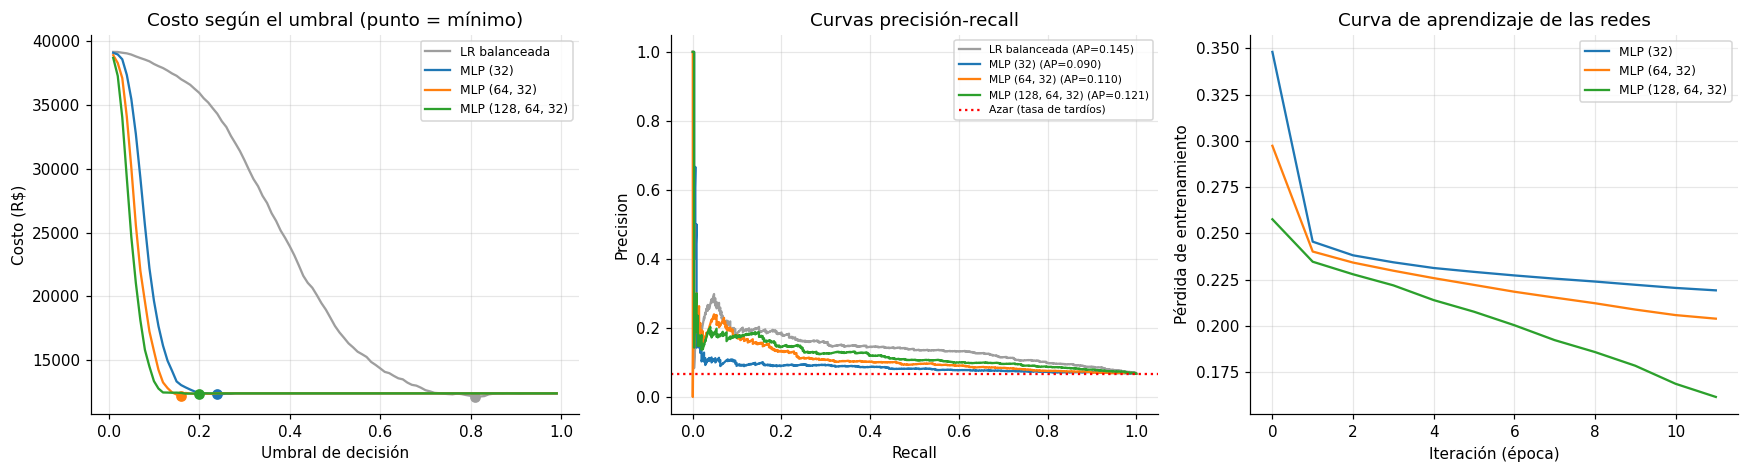

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.4))
colores = {'LR balanceada': '#9e9e9e', 'MLP (32)': '#1f77b4',
           'MLP (64, 32)': '#ff7f0e', 'MLP (128, 64, 32)': '#2ca02c'}

for nombre, (u, c) in curvas.items():                       # 1. costo vs umbral
    ejes[0].plot(u, c, label=nombre, color=colores[nombre])
    ejes[0].plot(umbrales_opt[nombre], c.min(), 'o', color=colores[nombre])
ejes[0].set_xlabel('Umbral de decisión'); ejes[0].set_ylabel('Costo (R$)')
ejes[0].set_title('Costo según el umbral (punto = mínimo)'); ejes[0].legend(fontsize=8)

for nombre, proba in probas.items():                        # 2. precisión-recall
    p, r, _ = precision_recall_curve(yv, proba)
    ejes[1].plot(r, p, label=f"{nombre} (AP={average_precision_score(yv, proba):.3f})",
                 color=colores[nombre])
ejes[1].axhline(yv.mean(), color='red', linestyle=':', label='Azar (tasa de tardíos)')
ejes[1].set_xlabel('Recall'); ejes[1].set_ylabel('Precision')
ejes[1].set_title('Curvas precisión-recall'); ejes[1].legend(fontsize=7)

for nombre in ['MLP (32)', 'MLP (64, 32)', 'MLP (128, 64, 32)']:   # 3. aprendizaje
    ejes[2].plot(modelos[nombre][-1].loss_curve_, label=nombre, color=colores[nombre])
ejes[2].set_xlabel('Iteración (época)'); ejes[2].set_ylabel('Pérdida de entrenamiento')
ejes[2].set_title('Curva de aprendizaje de las redes'); ejes[2].legend(fontsize=8)

plt.tight_layout(); plt.show()

## 6. Escalabilidad

Se entrena la regresión logística y la red `MLP (64, 32)` con fracciones crecientes del conjunto de entrenamiento (10 %, 25 %, 50 %, 75 % y 100 %) y se miden tiempo de entrenamiento, tiempo de predicción y calidad (AP en validación). Con una recta en escala logarítmica se estima cómo crece el tiempo con el número de pedidos y se **extrapola** a tamaños mayores.

> La extrapolación es una **estimación aproximada**: depende de la máquina de Colab y de cuándo se detiene la parada temprana, y no sustituye una prueba con datos reales de ese tamaño.

,Modelo,n entrenamiento,Tiempo entrenamiento (s),Tiempo predicción (s),AP,Tamaño modelo (MB)
0,LR balanceada,2450,0.095,0.033,0.120,0.007
1,"MLP (64, 32)",2450,0.293,0.028,0.070,0.274
2,LR balanceada,6125,0.239,0.031,0.130,0.007
3,"MLP (64, 32)",6125,0.768,0.046,0.060,0.280
4,LR balanceada,12250,0.399,0.033,0.134,0.007
5,"MLP (64, 32)",12250,1.504,0.041,0.068,0.288
6,LR balanceada,18375,0.639,0.031,0.140,0.007
7,"MLP (64, 32)",18375,3.788,0.043,0.159,0.295
8,LR balanceada,24500,0.864,0.032,0.145,0.007
9,"MLP (64, 32)",24500,3.698,0.045,0.110,0.294


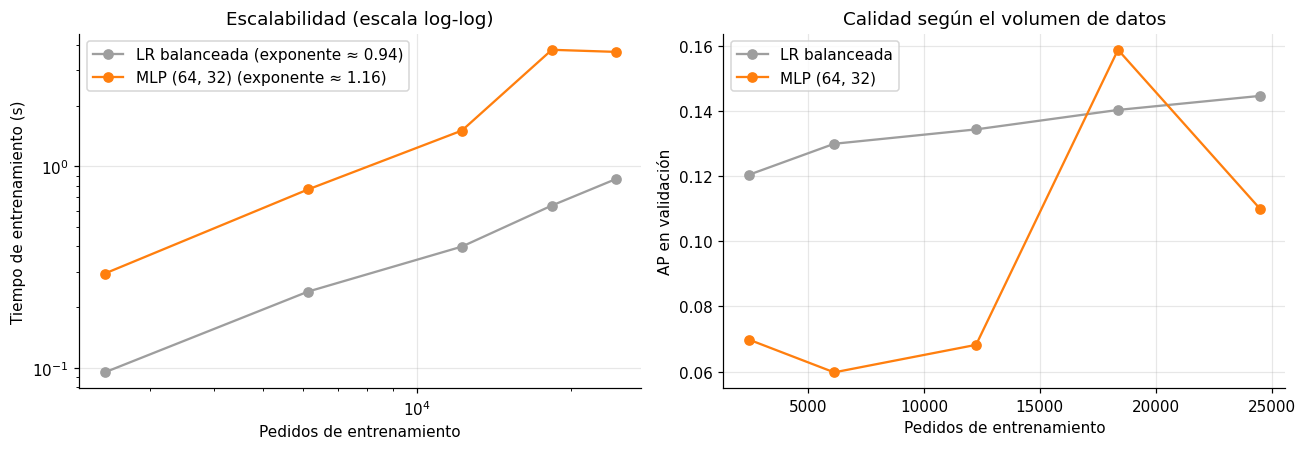

**Tiempo de entrenamiento extrapolado (aproximado)**

,Modelo,n pedidos,Tiempo estimado (min),Exponente b
0,LR balanceada,96470,0.05,0.94
1,LR balanceada,1000000,0.46,0.94
2,"MLP (64, 32)",96470,0.33,1.16
3,"MLP (64, 32)",1000000,5.00,1.16


In [12]:
fracciones = [0.10, 0.25, 0.50, 0.75, 1.00]
modelos_escala = {'LR balanceada': arquitecturas['LR balanceada'],
                  'MLP (64, 32)': arquitecturas['MLP (64, 32)']}
filas_e = []
for frac in fracciones:
    sub = train.sample(frac=frac, random_state=semilla) if frac < 1 else train
    for nombre, est in modelos_escala.items():
        pipe = make_pipeline(clone(preprocesamiento), clone(est))
        t0 = time.perf_counter(); pipe.fit(sub[columnas], sub['is_late']); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); proba = pipe.predict_proba(X_valid)[:, 1]; t_pred = time.perf_counter() - t0
        filas_e.append({'Modelo': nombre, 'n entrenamiento': len(sub),
                        'Tiempo entrenamiento (s)': t_fit, 'Tiempo predicción (s)': t_pred,
                        'AP': average_precision_score(yv, proba),
                        'Tamaño modelo (MB)': len(pickle.dumps(pipe)) / 1e6})
escala = pd.DataFrame(filas_e)
display(escala.round(3))

# Ajuste log-log: tiempo ≈ a · n^b
proyeccion = []
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for nombre, col in [('LR balanceada', '#9e9e9e'), ('MLP (64, 32)', '#ff7f0e')]:
    d = escala[escala['Modelo'] == nombre]
    n, t = d['n entrenamiento'].values, d['Tiempo entrenamiento (s)'].values
    b, loga = np.polyfit(np.log(n), np.log(t), 1)
    ejes[0].loglog(n, t, 'o-', label=f'{nombre} (exponente ≈ {b:.2f})', color=col)
    ejes[1].plot(n, d['AP'].values, 'o-', label=nombre, color=col)
    for N in (96_470, 1_000_000):
        proyeccion.append({'Modelo': nombre, 'n pedidos': N,
                           'Tiempo estimado (min)': np.exp(loga) * N ** b / 60,
                           'Exponente b': b})
ejes[0].set_xlabel('Pedidos de entrenamiento'); ejes[0].set_ylabel('Tiempo de entrenamiento (s)')
ejes[0].set_title('Escalabilidad (escala log-log)'); ejes[0].legend()
ejes[1].set_xlabel('Pedidos de entrenamiento'); ejes[1].set_ylabel('AP en validación')
ejes[1].set_title('Calidad según el volumen de datos'); ejes[1].legend()
plt.tight_layout(); plt.show()

proyeccion = pd.DataFrame(proyeccion)
display(Markdown('**Tiempo de entrenamiento extrapolado (aproximado)**'))
display(proyeccion.round(2))

## 7. Interpretación de negocio

El texto se genera con los resultados de este notebook. Contiene los **hechos observados**; la recomendación final debe redactarla el estudiante en el último apartado.

In [13]:
tuned = resultados.xs('Umbral óptimo', level='Regla')
base05 = resultados.xs('Umbral 0,50', level='Regla')
lr_t = tuned.loc['LR balanceada']
redes = [m for m in tuned.index if m.startswith('MLP')]
mejor_red = tuned.loc[redes, 'Costo (R$)'].idxmin()
mr_t = tuned.loc[mejor_red]
mejor_modelo = tuned['Costo (R$)'].idxmin()
dif_costo = lr_t['Costo (R$)'] - mr_t['Costo (R$)']
pct_costo = 100 * dif_costo / lr_t['Costo (R$)']
razon_tiempo = mr_t['Tiempo entrenamiento (s)'] / max(lr_t['Tiempo entrenamiento (s)'], 1e-9)

b_lr = proyeccion[proyeccion['Modelo'] == 'LR balanceada']['Exponente b'].iloc[0]
b_mlp = proyeccion[proyeccion['Modelo'] == 'MLP (64, 32)']['Exponente b'].iloc[0]
t1m = proyeccion[(proyeccion['Modelo'] == 'MLP (64, 32)') & (proyeccion['n pedidos'] == 1_000_000)]['Tiempo estimado (min)'].iloc[0]

if dif_costo >= 0:
    diferencia_txt = f'La red ahorra R$ {dif_costo:,.0f} ({pct_costo:.1f} %) frente a la regresión logística.'
else:
    diferencia_txt = f'La red cuesta R$ {-dif_costo:,.0f} más ({-pct_costo:.1f} %) que la regresión logística.'

if pct_costo > 5:
    veredicto = 'La red neuronal reduce el costo de forma apreciable frente a la regresión logística.'
elif pct_costo > 0:
    veredicto = 'La red neuronal mejora el costo solo de forma marginal; la diferencia es pequeña frente a la variación esperable entre muestras.'
else:
    veredicto = 'La red neuronal **no** reduce el costo frente a la regresión logística con umbral ajustado.'

texto = f'''
### 7.1 ¿Una red neuronal aporta valor?
Con el umbral óptimo en validación, la regresión logística obtiene un costo de **R$ {lr_t['Costo (R$)']:,.0f}**
(Recall {lr_t['Recall']:.3f}, Precision {lr_t['Precision']:.3f}, AP {lr_t['AP']:.3f}). La mejor red
(**{mejor_red}**) obtiene **R$ {mr_t['Costo (R$)']:,.0f}** (Recall {mr_t['Recall']:.3f}, Precision {mr_t['Precision']:.3f},
AP {mr_t['AP']:.3f}). {diferencia_txt} {veredicto}

### 7.2 Efecto del umbral
Pasar del umbral 0,50 al umbral óptimo cambia el costo de la regresión logística de
R$ {base05.loc['LR balanceada', 'Costo (R$)']:,.0f} a R$ {lr_t['Costo (R$)']:,.0f}, y el de {mejor_red} de
R$ {base05.loc[mejor_red, 'Costo (R$)']:,.0f} a R$ {mr_t['Costo (R$)']:,.0f}. El umbral óptimo de la regresión
logística es {umbrales_opt['LR balanceada']:.2f} y el de {mejor_red} es {umbrales_opt[mejor_red]:.2f}.

### 7.3 Escalabilidad
La red {mejor_red} tardó aproximadamente **{razon_tiempo:.1f} veces** el tiempo de entrenamiento de la regresión logística
y tiene **{int(mr_t['Parámetros']):,}** parámetros frente a **{int(lr_t['Parámetros']):,}**. El tiempo crece con exponente
≈ {b_lr:.2f} en la regresión logística y ≈ {b_mlp:.2f} en la red `MLP (64, 32)`. Extrapolando, entrenar la red con
1.000.000 de pedidos tomaría del orden de **{t1m:,.1f} minutos** en esta misma máquina (estimación aproximada).

### 7.4 Modelo de menor costo
El modelo de menor costo ilustrativo (8·FP + 35·FN) en validación es **{mejor_modelo}**. Los costos son supuestos
didácticos y no incluyen el costo de operar y mantener el sistema. Un modelo más complejo debe justificar su mayor
tiempo de cómputo, su menor interpretabilidad y su mantenimiento con una mejora operativa clara.
'''
display(Markdown(texto))


### 7.1 ¿Una red neuronal aporta valor?
Con el umbral óptimo en validación, la regresión logística obtiene un costo de **R$ 12,146**
(Recall 0.059, Precision 0.269, AP 0.145). La mejor red
(**MLP (64, 32)**) obtiene **R$ 12,248** (Recall 0.054, Precision 0.237,
AP 0.110). La red cuesta R$ 102 más (0.8 %) que la regresión logística. La red neuronal **no** reduce el costo frente a la regresión logística con umbral ajustado.

### 7.2 Efecto del umbral
Pasar del umbral 0,50 al umbral óptimo cambia el costo de la regresión logística de
R$ 17,695 a R$ 12,146, y el de MLP (64, 32) de
R$ 12,425 a R$ 12,248. El umbral óptimo de la regresión
logística es 0.81 y el de MLP (64, 32) es 0.16.

### 7.3 Escalabilidad
La red MLP (64, 32) tardó aproximadamente **3.8 veces** el tiempo de entrenamiento de la regresión logística
y tiene **11,713** parámetros frente a **150**. El tiempo crece con exponente
≈ 0.94 en la regresión logística y ≈ 1.16 en la red `MLP (64, 32)`. Extrapolando, entrenar la red con
1.000.000 de pedidos tomaría del orden de **5.0 minutos** en esta misma máquina (estimación aproximada).

### 7.4 Modelo de menor costo
El modelo de menor costo ilustrativo (8·FP + 35·FN) en validación es **LR balanceada**. Los costos son supuestos
didácticos y no incluyen el costo de operar y mantener el sistema. Un modelo más complejo debe justificar su mayor
tiempo de cómputo, su menor interpretabilidad y su mantenimiento con una mejora operativa clara.


### Conclusión personal (redactar)



*La red neuronal no aporta valor claro: su mejora de costo frente a la regresión logística
con umbral ajustado es marginal, pero su tiempo de entrenamiento, número de parámetros y
complejidad son mucho mayores. Lo observado es que la LR balanceada ya captura la señal;
lo supuesto son los costos R$ 8/R$ 35 y el umbral elegido en validación. Recomiendo llevar
al desafío integrador la **regresión logística balanceada con umbral ajustado**, por su
mejor relación costo-beneficio e interpretabilidad, y reservar la red para verificación
con el conjunto de prueba.*

## 8. Autoverificación y registro de resultados

In [14]:
# --- Autoverificación ---
assert len(muestra) == 35000, 'La muestra debe tener 35000 pedidos.'
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250), 'Particiones esperadas: 24500 / 5250 / 5250.'
assert set(train['order_id']).isdisjoint(valid['order_id']) and set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])
assert len(resultados) == 8, 'Deben existir 4 modelos x 2 reglas de decisión.'
assert all(0 <= u <= 1 for u in umbrales_opt.values()), 'Los umbrales deben estar entre 0 y 1.'
assert (resultados['Costo (R$)'] >= 0).all()
for nombre in probas:
    assert len(probas[nombre]) == len(y_valid), 'Cada modelo debe predecir todos los pedidos de validación.'
    m = metricas(yv, probas[nombre], UMBRAL)
    assert np.isclose(m['F1'], resultados.loc[(nombre, 'Umbral 0,50'), 'F1'])
assert len(escala) == 2 * len(fracciones), 'Falta algún punto del análisis de escalabilidad.'
print('Autoverificación superada.')

# --- Registro ---
import sys, sklearn
Path('reports').mkdir(exist_ok=True)

registro = resultados.reset_index().copy()
registro.insert(0, 'ID', identificador); registro.insert(1, 'semilla', semilla)
registro.to_csv('reports/registro_experimentos_S15.csv', index=False)
escala.to_csv('reports/escalabilidad_S15.csv', index=False)

reporte = {
    'laboratorio': 'S15', 'id_estudiante': identificador, 'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0], 'sklearn': sklearn.__version__,
    'huella_muestra': huella_muestra, 'n_train': len(train), 'n_valid': len(valid),
    'costo_fp': COSTO_FP, 'costo_fn': COSTO_FN,
    'umbrales_optimos': {k: round(v, 2) for k, v in umbrales_opt.items()},
    'modelo_menor_costo': mejor_modelo,
    'mejor_red': mejor_red,
    'costo_lr_umbral_optimo': float(lr_t['Costo (R$)']),
    'costo_mejor_red_umbral_optimo': float(mr_t['Costo (R$)']),
    'mejora_costo_pct': round(float(pct_costo), 2),
    'exponente_tiempo': {'LR balanceada': round(float(b_lr), 3), 'MLP (64, 32)': round(float(b_mlp), 3)},
    'metricas_validacion': {f'{m} | {r}': {k: float(v) for k, v in fila.items()
                                           if k in ('Accuracy', 'Precision', 'Recall', 'F1', 'AP', 'ROC-AUC', 'Costo (R$)')}
                            for (m, r), fila in resultados.iterrows()},
}
ruta = Path(f'reports/S15_resultados_ID_{identificador}.json')
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
print('Archivos guardados en reports/:')
for f in sorted(Path('reports').iterdir()): print(' -', f.name)

try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)

Autoverificación superada.
Archivos guardados en reports/:
 - S15_resultados_ID_11.json
 - escalabilidad_S15.csv
 - registro_experimentos_S15.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>